# Experiment No: 20

## K-Means Clustering Algorithm for a Given Data Set

**Aim:** To understand the K-means clustering algorithm for the given Mall Customers data set.

In [1]:
%pip install -q scikit-learn
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

data = {
    'CustomerID': [
        1, 3, 5, 7, 9, 11, 13, 15,
        17, 19, 21, 23, 25, 27, 29, 31,
        33, 35, 37, 39, 41, 43, 45, 47,
        49, 51, 53, 55, 57, 59, 61, 63,
        65, 67, 69, 71, 73, 75, 77, 79,
        81, 83, 85, 87, 89, 91, 93, 95,
        97, 99, 101, 103, 105, 107, 109, 111,
        113, 115, 117, 119, 121, 123, 125, 127,
        129, 131, 133, 135, 137, 139, 141, 143,
        145, 147, 149, 151, 153, 155, 157, 159,
        161, 163, 165, 167, 169, 171, 173, 175,
        177, 179, 181, 183, 185, 187, 189, 191,
        193, 195, 197, 199
    ],
    'Gender': [
        'Male', 'Female', 'Female', 'Female', 'Male', 'Male', 'Female', 'Male',
        'Female', 'Male', 'Male', 'Female', 'Female', 'Female', 'Female', 'Male',
        'Male', 'Female', 'Female', 'Female', 'Female', 'Male', 'Female', 'Female',
        'Female', 'Female', 'Female', 'Female', 'Female', 'Female', 'Male', 'Female',
        'Male', 'Female', 'Male', 'Male', 'Female', 'Male', 'Female', 'Female',
        'Male', 'Male', 'Female', 'Female', 'Female', 'Female', 'Male', 'Female',
        'Female', 'Male', 'Female', 'Male', 'Male', 'Female', 'Male', 'Male',
        'Female', 'Female', 'Female', 'Female', 'Male', 'Female', 'Female', 'Male',
        'Male', 'Male', 'Female', 'Male', 'Female', 'Male', 'Female', 'Female',
        'Male', 'Male', 'Female', 'Male', 'Female', 'Female', 'Male', 'Male',
        'Female', 'Male', 'Male', 'Male', 'Female', 'Male', 'Male', 'Female',
        'Male', 'Male', 'Female', 'Male', 'Female', 'Female', 'Female', 'Female',
        'Male', 'Female', 'Female', 'Male'
    ],
    'Age': [
        19, 20, 31, 35, 64, 67, 58, 37,
        35, 52, 35, 46, 54, 45, 40, 60,
        53, 49, 42, 36, 65, 48, 49, 50,
        29, 49, 31, 50, 51, 27, 70, 67,
        63, 43, 19, 70, 60, 59, 45, 23,
        57, 67, 21, 55, 34, 68, 48, 32,
        47, 48, 23, 67, 49, 66, 68, 65,
        38, 18, 63, 51, 27, 40, 23, 43,
        59, 47, 25, 20, 44, 19, 57, 28,
        25, 48, 34, 43, 44, 47, 37, 34,
        56, 19, 50, 42, 36, 40, 36, 52,
        58, 59, 37, 46, 41, 54, 41, 34,
        33, 47, 45, 32
    ],
    'Annual Income (k$)': [
        15, 16, 17, 18, 19, 19, 20, 20,
        21, 23, 24, 25, 28, 28, 29, 30,
        33, 33, 34, 37, 38, 39, 39, 40,
        40, 42, 43, 43, 44, 46, 46, 47,
        48, 48, 48, 49, 50, 54, 54, 54,
        54, 54, 54, 57, 58, 59, 60, 60,
        60, 61, 62, 62, 62, 63, 63, 63,
        64, 65, 65, 67, 67, 69, 70, 71,
        71, 71, 72, 73, 73, 74, 75, 76,
        77, 77, 78, 78, 78, 78, 78, 78,
        79, 81, 85, 86, 87, 87, 87, 88,
        88, 93, 97, 98, 99, 101, 103, 103,
        113, 120, 126, 137
    ],
    'Spending Score (1-100)': [
        39, 6, 40, 6, 3, 14, 15, 13,
        35, 29, 35, 5, 14, 32, 31, 4,
        4, 14, 17, 26, 35, 36, 28, 55,
        42, 52, 54, 45, 50, 51, 56, 52,
        51, 50, 59, 55, 49, 47, 53, 52,
        51, 41, 57, 58, 60, 55, 49, 42,
        47, 42, 41, 59, 56, 50, 43, 52,
        42, 48, 43, 43, 56, 58, 29, 35,
        11, 9, 34, 5, 7, 10, 5, 40,
        12, 36, 22, 17, 20, 16, 1, 1,
        35, 5, 26, 20, 27, 13, 10, 13,
        15, 14, 32, 15, 39, 24, 17, 23,
        8, 16, 28, 18
    ],
}
pd.DataFrame(data).to_csv('Mall_Customers.csv', index=False)

df = pd.read_csv('Mall_Customers.csv')
df.info()

Note: you may need to restart the kernel to use updated packages.


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              100 non-null    int64 
 1   Gender                  100 non-null    object
 2   Age                     100 non-null    int64 
 3   Annual Income (k$)      100 non-null    int64 
 4   Spending Score (1-100)  100 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 4.0+ KB


In [2]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,3,Female,20,16,6
2,5,Female,31,17,40
3,7,Female,35,18,6
4,9,Male,64,19,3


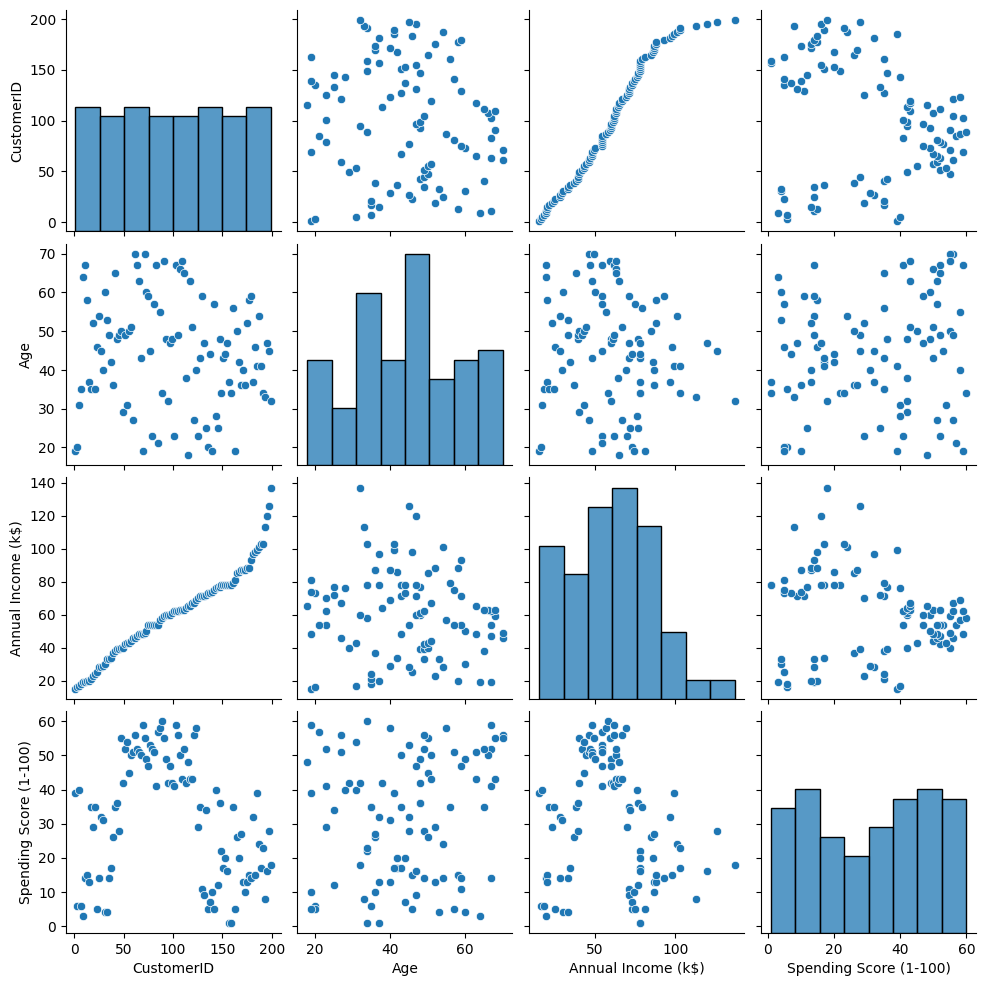

In [3]:
sns.pairplot(df)
plt.show()

In [4]:
features = df.iloc[:, [3, 4]].values  # Annual Income and Spending Score

from sklearn.cluster import KMeans
model = KMeans(n_clusters=5, n_init=10, random_state=42)
model.fit(features)

,n_clusters,5
,init,'k-means++'
,n_init,10
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,42
,copy_x,True
,algorithm,'lloyd'


In [5]:
Final = df.iloc[:, [3, 4]].copy()
Final['label'] = model.predict(features)
Final.head()

,Annual Income (k$),Spending Score (1-100),label
0,15,39,0
1,16,6,4
2,17,40,0
3,18,6,4
4,19,3,4


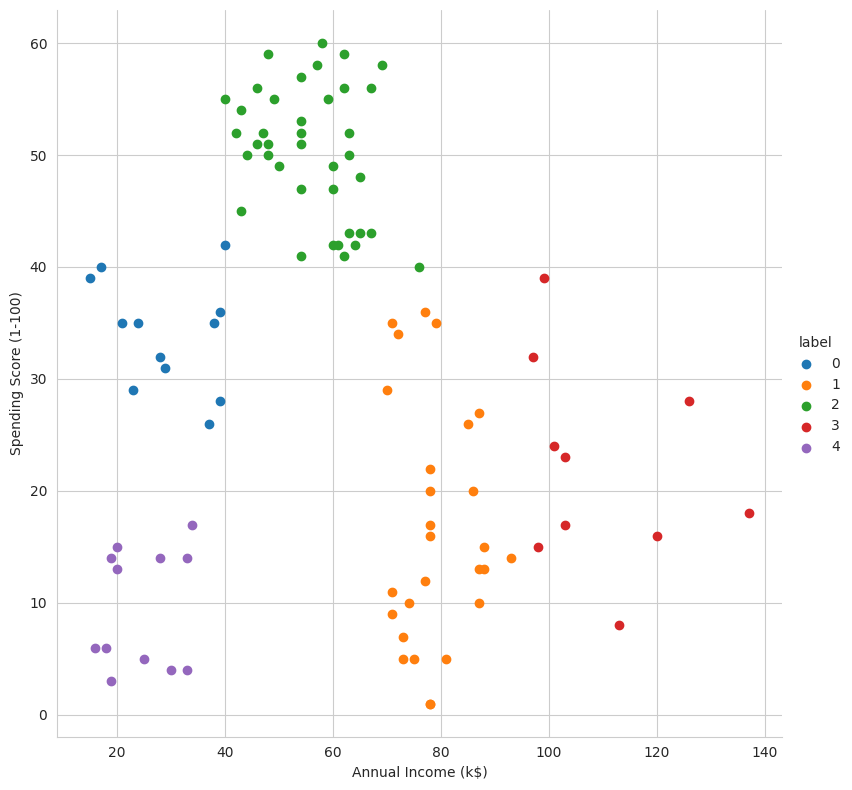

In [6]:
sns.set_style("whitegrid")
sns.FacetGrid(Final, hue="label", height=8) \
    .map(plt.scatter, "Annual Income (k$)", "Spending Score (1-100)") \
    .add_legend()
plt.show()

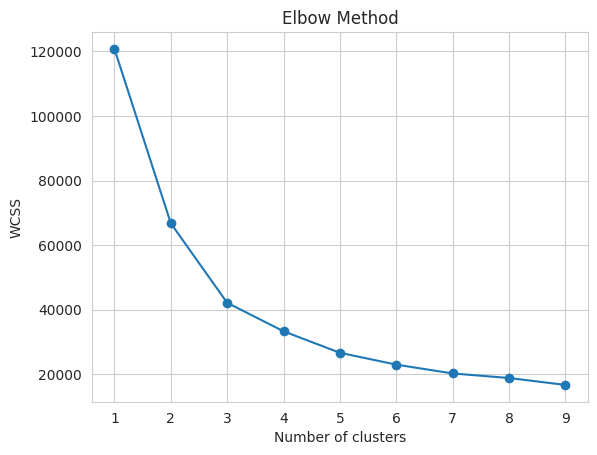

In [7]:
features_el = df.iloc[:, [2, 3, 4]].values  # Age, Annual Income, Spending Score

wcss = []
for i in range(1, 10):
    model = KMeans(n_clusters=i, n_init=10, random_state=42)
    model.fit(features_el)
    wcss.append(model.inertia_)

plt.plot(range(1, 10), wcss, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')
plt.show()